In [1]:
import pandas as pd
import numpy as np
import koreanize_matplotlib
%config InlineBackend.figure_format = 'retina'
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv('movie_finished_toFDA_수익성.csv', encoding='cp949')

In [3]:
df

In [4]:
def calculate_drop_point(df, movie_title):
    """
    영화의 drop_point를 계산하는 함수.
    
    Args:
    df (pd.DataFrame): 데이터프레임 (columns: 'movie_title', 'DoW', '관객수')
    movie_title (str): 분석할 영화 제목
    
    Returns:
    float: drop_point 값
    """
    # 1. 필요한 데이터 필터링
    movie_weekend = df[
        (df['movie_title'] == movie_title) &
        (df['DoW'].isin(['Friday', 'Saturday', 'Sunday']))
    ].reset_index(drop=True)
    
    # 데이터 검증: 주차별 데이터가 충분한지 확인
    if len(movie_weekend) < 6:
        raise ValueError("데이터가 충분하지 않습니다. 최소 첫째 주와 둘째 주의 주말 관객수 데이터가 필요합니다.")
    
    # 2. 주차별 주말 관객 수 계산
    첫째주_주말_관객수 = movie_weekend.iloc[0:3]['관객수'].sum()
    둘째주_주말_관객수 = movie_weekend.iloc[3:6]['관객수'].sum()
    
    # 3. drop_point 계산
    drop_point = 1 - (둘째주_주말_관객수 / 첫째주_주말_관객수)
    
    return drop_point

In [5]:
wk_drop_ratio = []

# df에서 영화 제목을 가져와서 drop_point 계산
movie_title = df['movie_title'].unique()

for i in movie_title:
    try:
        drop_point = calculate_drop_point(df, i)
    except ValueError:
        drop_point = None  # 데이터가 부족할 경우 None으로 처리
    wk_drop_ratio.append({'movie_title': i, 'drop_ratio': drop_point})

drop_ratio_df = pd.DataFrame(wk_drop_ratio)

# 기존 df에 drop_ratio 추가
df = pd.merge(df, drop_ratio_df, on='movie_title', how='left')

df

In [6]:
# 날짜를 datetime으로 변환 및 정렬
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by=['movie_title', 'Date']).reset_index(drop=True)

# 영화별로 week1_change(8일차-1일차)와 week2_change(15일차-8일차) 계산
def calculate_weekly_changes_by_date(df):
    result = []

    # 각 영화별 처리
    for movie in df['movie_title'].unique():
        movie_df = df[df['movie_title'] == movie]
        changes = {'movie_title': movie}

        # 1일차, 8일차, 15일차 값 가져오기
        if len(movie_df) >= 8:  # 최소 8일차 데이터 필요
            day1_value = movie_df.iloc[0]['영화명_검색량']
            day8_value = movie_df.iloc[7]['영화명_검색량']
            changes['week1_change'] = day8_value / day1_value

        if len(movie_df) >= 15:  # 최소 15일차 데이터 필요
            day15_value = movie_df.iloc[14]['영화명_검색량']
            changes['week2_change'] = day15_value / day8_value

        result.append(changes)

    return pd.DataFrame(result)

# 계산 및 병합
weekly_changes = calculate_weekly_changes_by_date(df)
df = pd.merge(df, weekly_changes, on='movie_title', how='left')

# 결과 출력
print(df)

/var/folders/7j/q4f5lfds7cn41ftj48m1vkn40000gn/T/ipykernel_47772/648153953.py:22: RuntimeWarning: divide by zero encountered in scalar divide
  changes['week2_change'] = day15_value / day8_value


      naver_movie_code  kobis_movie_code movie_title release_date DoW_release  \
0               177371          20188144      0.0MHz   2019-05-29   Wednesday   
1               177371          20188144      0.0MHz   2019-05-29   Wednesday   
2               177371          20188144      0.0MHz   2019-05-29   Wednesday   
3               177371          20188144      0.0MHz   2019-05-29   Wednesday   
4               177371          20188144      0.0MHz   2019-05-29   Wednesday   
...                ...               ...         ...          ...         ...   
6130            147092          20167363      히든 피겨스   2017-03-23    Thursday   
6131            147092          20167363      히든 피겨스   2017-03-23    Thursday   
6132            147092          20167363      히든 피겨스   2017-03-23    Thursday   
6133            147092          20167363      히든 피겨스   2017-03-23    Thursday   
6134            147092          20167363      히든 피겨스   2017-03-23    Thursday   

           Date        DoW 

/var/folders/7j/q4f5lfds7cn41ftj48m1vkn40000gn/T/ipykernel_47772/648153953.py:18: RuntimeWarning: invalid value encountered in scalar divide
  changes['week1_change'] = day8_value / day1_value
/var/folders/7j/q4f5lfds7cn41ftj48m1vkn40000gn/T/ipykernel_47772/648153953.py:22: RuntimeWarning: invalid value encountered in scalar divide
  changes['week2_change'] = day15_value / day8_value


In [7]:
print(df[['movie_title', 'Date', 'DoW', '영화명_검색량', 'week1_change', 'week2_change']].head(20))

   movie_title       Date        DoW   영화명_검색량  week1_change  week2_change
0       0.0MHz 2019-05-29  Wednesday   0.16828      0.095317      4.240025
1       0.0MHz 2019-05-30   Thursday   0.02754      0.095317      4.240025
2       0.0MHz 2019-05-31     Friday   0.01955      0.095317      4.240025
3       0.0MHz 2019-06-01   Saturday   0.02116      0.095317      4.240025
4       0.0MHz 2019-06-02     Sunday   0.02394      0.095317      4.240025
5       0.0MHz 2019-06-03     Monday   0.02099      0.095317      4.240025
6       0.0MHz 2019-06-04    Tuesday   0.01634      0.095317      4.240025
7       0.0MHz 2019-06-05  Wednesday   0.01604      0.095317      4.240025
8       0.0MHz 2019-06-06   Thursday   0.01170      0.095317      4.240025
9       0.0MHz 2019-06-07     Friday   0.01055      0.095317      4.240025
10      0.0MHz 2019-06-08   Saturday   0.01642      0.095317      4.240025
11      0.0MHz 2019-06-09     Sunday   0.01000      0.095317      4.240025
12      0.0MHz 2019-06-10

In [8]:
df.columns

In [9]:
# 매출액, 수익성, 평점, 드랍률
columns_to_analyze = ['누적_매출액', '규모_수익성', 'NTZ_score_total', 'drop_ratio']

# NaN 제거 후 상관 분석 데이터프레임 생성
correlation_df = df[columns_to_analyze].dropna().corr()

# 결과 출력
print("상관 분석 결과:")
print(correlation_df)

상관 분석 결과:
                   누적_매출액    규모_수익성  NTZ_score_total  drop_ratio
누적_매출액           1.000000  0.547443         0.097950   -0.308419
규모_수익성           0.547443  1.000000         0.362761   -0.637229
NTZ_score_total  0.097950  0.362761         1.000000   -0.430890
drop_ratio      -0.308419 -0.637229        -0.430890    1.000000


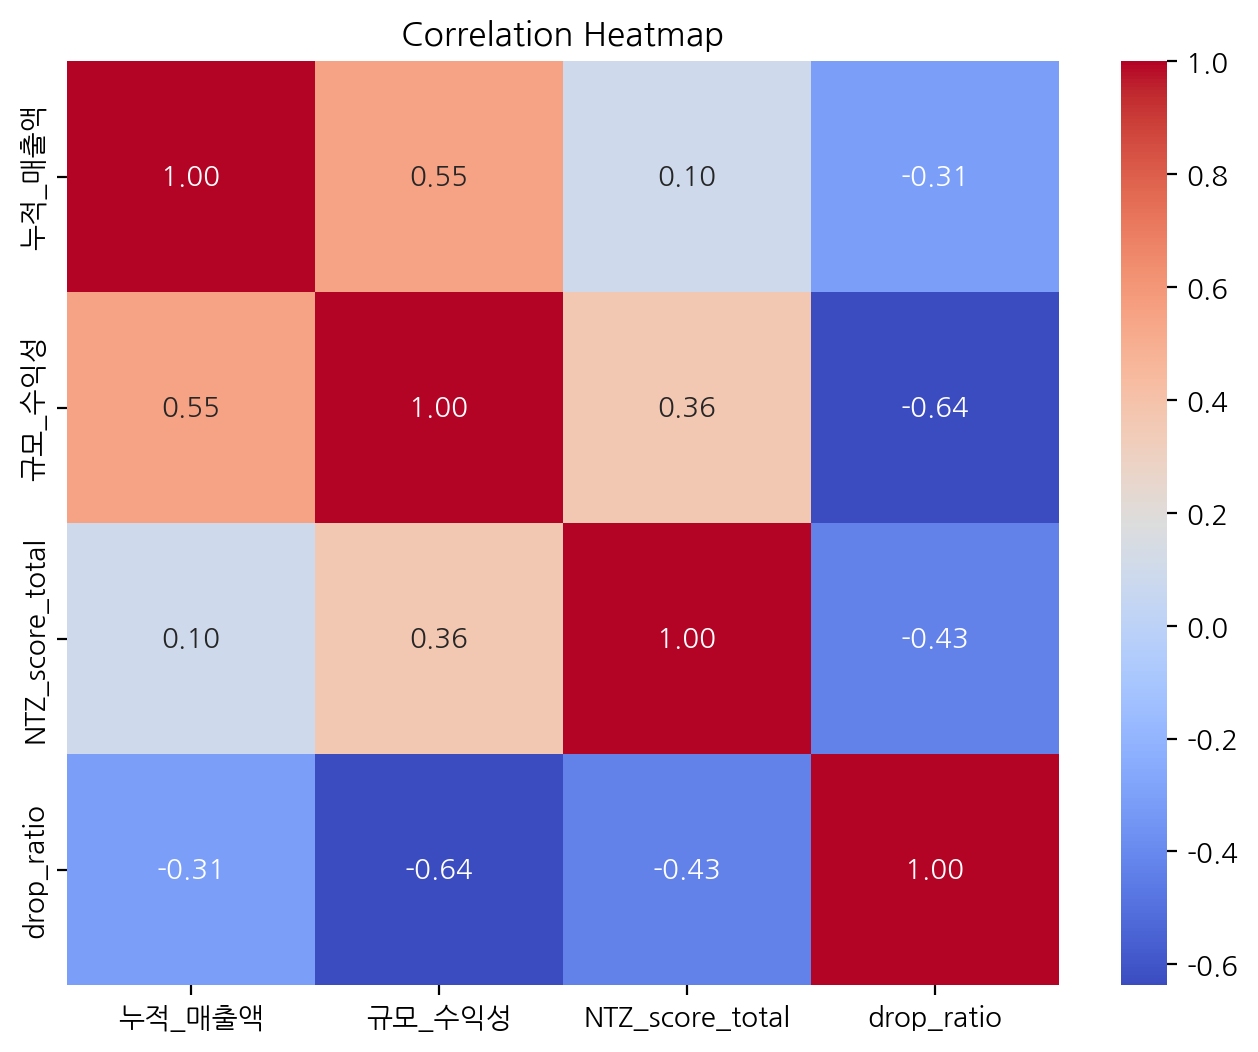

In [10]:
# 히트맵1
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_df, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap")
plt.show()

In [12]:
# 매출액, 수익성, 평점, 드랍률, 주차별 검색량 변화
columns_to_analyze = ['누적_매출액', '규모_수익성', 'NTZ_score_total', 'drop_ratio', 'week1_change', 'week2_change']

# NaN 제거 후 상관 분석 데이터프레임 생성
correlation_df = df[columns_to_analyze].dropna().corr()

# 결과 출력
print("상관 분석 결과:")
print(correlation_df)

상관 분석 결과:
                   누적_매출액    규모_수익성  NTZ_score_total  drop_ratio  \
누적_매출액           1.000000  0.552033         0.099240   -0.308489   
규모_수익성           0.552033  1.000000         0.361150   -0.639538   
NTZ_score_total  0.099240  0.361150         1.000000   -0.431296   
drop_ratio      -0.308489 -0.639538        -0.431296    1.000000   
week1_change    -0.036562  0.298249         0.244950   -0.411332   
week2_change    -0.037929 -0.062810        -0.075917    0.071717   

                 week1_change  week2_change  
누적_매출액              -0.036562     -0.037929  
규모_수익성               0.298249     -0.062810  
NTZ_score_total      0.244950     -0.075917  
drop_ratio          -0.411332      0.071717  
week1_change         1.000000     -0.058203  
week2_change        -0.058203      1.000000  


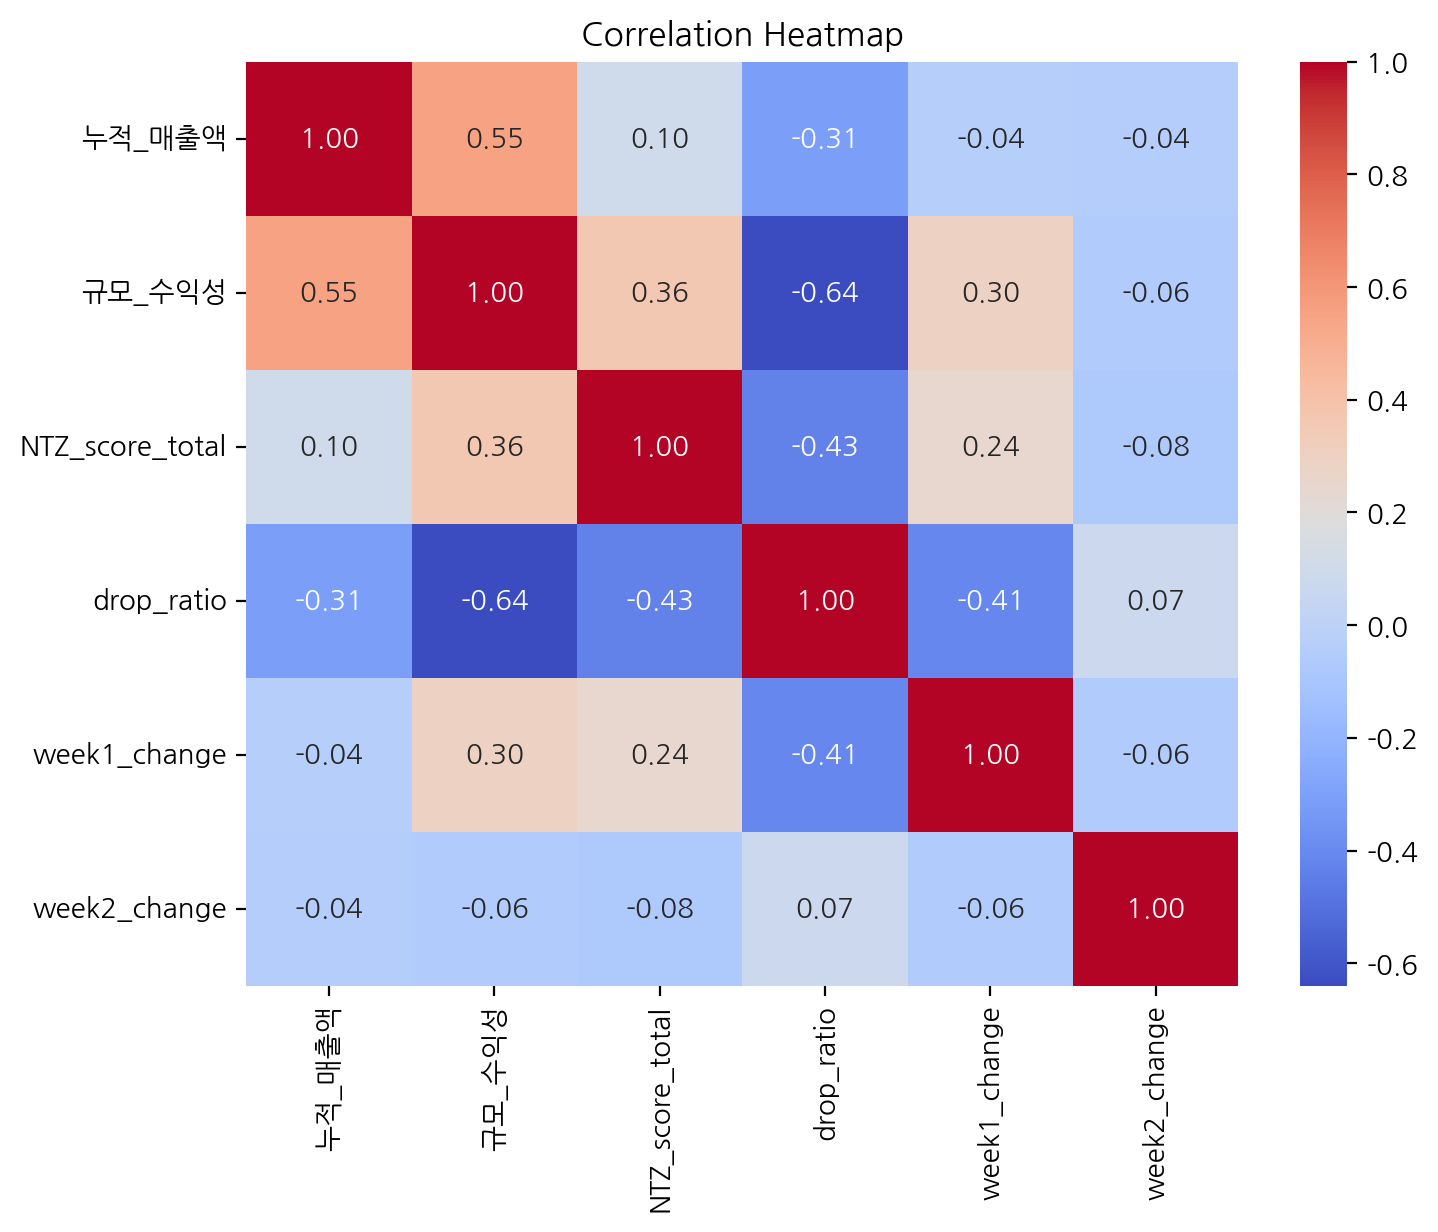

In [ ]:
# 히트맵1
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_df, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap")
plt.show()

In [15]:
df.to_csv('movie_finished_toFDA_수익성+드랍률+검색량변화.csv', index=False, encoding='cp949')

상관 분석 결과를 해석하겠습니다. 아래는 상관 계수를 바탕으로 주요 특징을 설명합니다:

---

### 주요 상관 관계 분석
1. **`누적_매출액`과 다른 변수의 상관 관계**:
   - **`규모_수익성` (0.547)**: 중간 정도의 양의 상관 관계가 있습니다. 이는 영화의 수익성이 높을수록 누적 매출액도 증가하는 경향이 있음을 나타냅니다.
   - **`NTZ_score_total` (0.098)**: 약한 양의 상관 관계입니다. NTZ 점수가 높은 영화가 매출과 약간의 관계가 있음을 시사하지만 강하지 않습니다.
   - **`drop_ratio` (-0.308)**: 약한 음의 상관 관계가 있습니다. 관객 감소 비율이 높은 영화일수록 누적 매출액이 낮은 경향을 보여줍니다.
   - **`week1_change` (-0.056)**: 거의 상관 관계가 없습니다. 첫 주의 검색량 변화와 누적 매출액 간의 직접적인 관계는 약합니다.
   - **`week2_change` (-0.188)**: 약한 음의 상관 관계입니다. 두 번째 주의 검색량 변화가 감소할수록 누적 매출액이 약간 낮아지는 경향을 보입니다.

2. **`규모_수익성`과 다른 변수의 상관 관계**:
   - **`NTZ_score_total` (0.363)**: 중간 정도의 양의 상관 관계입니다. 영화의 수익성과 NTZ 점수가 어느 정도 연관되어 있음을 나타냅니다.
   - **`drop_ratio` (-0.637)**: 강한 음의 상관 관계가 있습니다. 관객 감소 비율이 클수록 영화의 수익성이 낮아지는 경향이 강하게 나타납니다.
   - **`week1_change` (0.231)**: 약한 양의 상관 관계입니다. 첫 주 검색량 증가가 영화 수익성과 어느 정도 관련이 있음을 보여줍니다.
   - **`week2_change` (-0.102)**: 약한 음의 상관 관계입니다. 두 번째 주 검색량 변화와 수익성의 직접적인 관계는 약합니다.

3. **`NTZ_score_total`과 다른 변수의 상관 관계**:
   - **`drop_ratio` (-0.431)**: 중간 정도의 음의 상관 관계입니다. 관객 감소 비율이 높을수록 NTZ 점수가 낮아지는 경향이 있습니다.
   - **`week1_change` (0.363)**: 중간 정도의 양의 상관 관계입니다. 첫 주 검색량 변화가 NTZ 점수와 어느 정도 연관이 있음을 보여줍니다.
   - **`week2_change` (-0.034)**: 거의 상관 관계가 없습니다.

4. **`drop_ratio`와 다른 변수의 상관 관계**:
   - **`week1_change` (-0.313)**: 약한 음의 상관 관계입니다. 첫 주 검색량 변화가 감소할수록 관객 감소 비율이 커질 가능성이 있습니다.
   - **`week2_change` (0.160)**: 약한 양의 상관 관계입니다. 두 번째 주 검색량 증가가 관객 감소 비율 증가와 약간의 연관성을 가질 수 있습니다.

5. **`week1_change`와 `week2_change`**:
   - 상관 계수 (-0.309): 약한 음의 상관 관계가 있습니다. 첫 주와 두 번째 주의 검색량 변화는 서로 반대 경향을 보일 가능성이 있습니다.

---

### 종합적인 해석
- **수익성과 매출**:
  - `규모_수익성`은 `누적_매출액`과 중간 정도의 상관 관계가 있어, 영화의 수익성이 매출 성과에 중요한 요인임을 나타냅니다.
  - 높은 관객 감소 비율(`drop_ratio`)은 낮은 수익성과 관련이 있습니다.

- **검색량 변화와 변수 간 관계**:
  - 첫 주 검색량 변화(`week1_change`)는 `규모_수익성`과 `NTZ_score_total`에 약간의 긍정적 영향을 미치는 반면, 관객 감소 비율(`drop_ratio`)에는 약간 부정적인 영향을 미칩니다.
  - 두 번째 주 검색량 변화(`week2_change`)는 전반적으로 다른 변수와 약한 상관 관계를 보입니다.

- **관객 감소 비율의 영향**:
  - `drop_ratio`는 `규모_수익성`과 `NTZ_score_total`에 강한 음의 상관 관계를 나타내며, 이는 관객 감소가 영화의 성과에 부정적인 영향을 줄 수 있음을 보여줍니다.

---

### 전략적 인사이트
1. **첫 주 성과 강화**:
   - 첫 주 검색량 변화(`week1_change`)가 수익성과 NTZ 점수에 중요한 역할을 하므로, 개봉 첫 주에 강력한 마케팅을 추진할 필요가 있습니다.

2. **관객 유지 전략**:
   - `drop_ratio`를 낮추는 것이 수익성을 개선하는 데 매우 중요합니다. 이를 위해 관객 만족도를 높이는 콘텐츠 품질 관리와 지속적인 홍보 전략이 필요합니다.

3. **NTZ 점수 활용**:
   - NTZ 점수는 매출과 수익성에 중간 정도로 연관되어 있으므로, 긍정적인 평가를 받을 수 있는 마케팅과 평론가 리뷰 관리를 적극 활용해야 합니다.